In [2]:
!pwd
%cd CAGSubtraction/VM-UNet/models/vmunet
%load_ext autoreload
%autoreload 2

/home/share/clr/share/work
/home/share/clr/share/work/CAGSubtraction/VM-UNet/models/vmunet
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [13]:
import cagsegmamba as csm
import time
import torch
import torch.nn as nn
from PIL import Image
import numpy as np
import torchvision.transforms as transforms

img_path = "/home/share/clr/share/data/Coronary_nc_Dengzhenrong/images/test/IM000131_21.png"
img_path2 = "/home/share/clr/share/data/Coronary_nc_Dengzhenrong/images/test/IM000131_40.png"
img_path3 = "/home/share/clr/share/data/Coronary_nc_Dengzhenrong/images/test/IM000190_21.png"
img1 = np.array(Image.open(img_path).convert('RGB'), dtype=np.float32)
img2 = np.array(Image.open(img_path2).convert('RGB'), dtype=np.float32)
img3 = np.array(Image.open(img_path3).convert('RGB'), dtype=np.float32)
# print(img2.shape, (img2 == img).all())

# start_time = time.time()
img1 = transforms.ToTensor()(img1).unsqueeze(0)
img2 = transforms.ToTensor()(img2).unsqueeze(0)
img3 = transforms.ToTensor()(img3).unsqueeze(0)
imgs = torch.concat((img1, img2, img3), dim=0)

print(imgs.shape)

embed2d = csm.VesselEncPatchEmded2D(patch_size=4, in_chans=3, embed_dim=96, norm_layer=nn.LayerNorm)

outs = embed2d(imgs)

print(imgs.shape, outs.shape)


ModuleNotFoundError: No module named 'cagsegmamba'

torch.Size([2, 3, 512, 512])
torch.Size([2, 1, 512, 512])


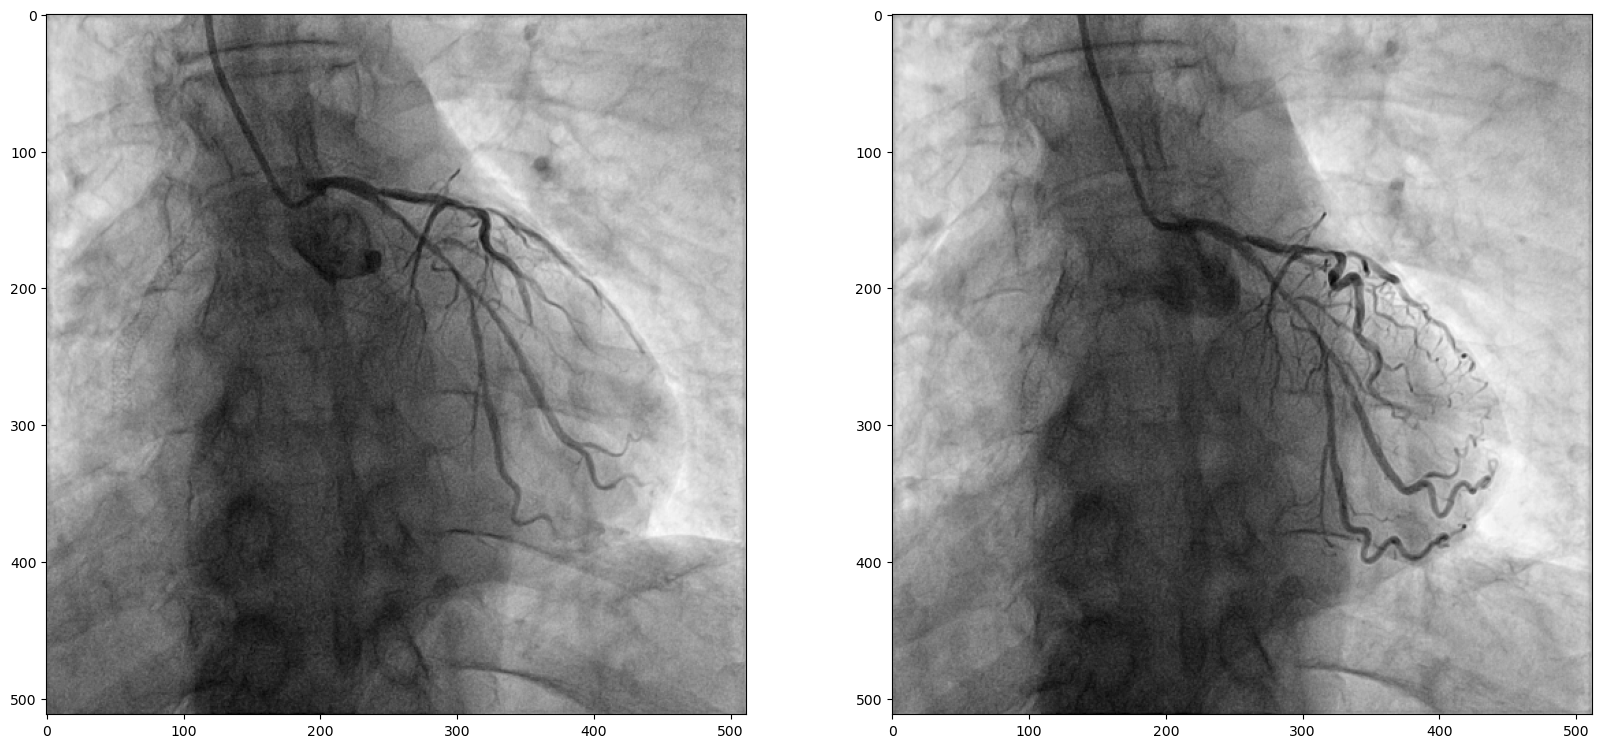

In [39]:
from matplotlib import pyplot as plt
img_path = "/home/share/clr/share/data/Coronary_nc_Dengzhenrong/images/test/IM000131_21.png"
img_path2 = "/home/share/clr/share/data/Coronary_nc_Dengzhenrong/images/test/IM000131_40.png"
img_path3 = "/home/share/clr/share/data/Coronary_nc_Dengzhenrong/images/test/IM000190_21.png"
img1 = np.array(Image.open(img_path).convert('RGB'), dtype=np.float32)
img2 = np.array(Image.open(img_path2).convert('RGB'), dtype=np.float32)
img3 = np.array(Image.open(img_path3).convert('RGB'), dtype=np.float32)
# print(img2.shape, (img2 == img).all())

# start_time = time.time()
img1 = transforms.ToTensor()(img1).unsqueeze(0)
img2 = transforms.ToTensor()(img2).unsqueeze(0)
img3 = transforms.ToTensor()(img3).unsqueeze(0)
imgs = torch.concat((img1, img2), dim=0)
print(imgs.shape)
grayscale = imgs[:,0,:,:].unsqueeze(1)
print(grayscale.shape)


plt.figure(figsize=(20, 20))
plt.subplot(2, 2, 1)
plt.imshow(grayscale[0,:,:,:].squeeze(), cmap='gray')
plt.subplot(2, 2, 2)
plt.imshow(grayscale[1,:,:,:].squeeze(), cmap='gray')

plt.show()